In [2]:
from pathlib import Path
import pandas as pd

root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

report_dir = root / "data" / "processed" / "report_tables"
report_dir.mkdir(parents=True, exist_ok=True)

saved = []

def save_df(obj, name):
    obj.to_csv(report_dir / name, index=False)
    saved.append(name)

if "metrics_html_df2" in globals():
    save_df(metrics_html_df2, "html_metrics_testset.csv")
elif "metrics_html_df" in globals():
    save_df(metrics_html_df, "html_metrics_testset.csv")

if "cv_html_df" in globals():
    save_df(cv_html_df, "html_metrics_cv5.csv")

if "rf_top_h" in globals():
    save_df(rf_top_h, "html_rf_top20_features.csv")

if "xgb_top_h" in globals():
    save_df(xgb_top_h, "html_xgb_top20_features.csv")

if "fp_th_h" in globals():
    fp_th_h.head(50).to_csv(report_dir / "html_fp_top50.csv", index=False)
    saved.append("html_fp_top50.csv")

if "fn_th_h" in globals():
    fn_th_h.head(50).to_csv(report_dir / "html_fn_top50.csv", index=False)
    saved.append("html_fn_top50.csv")

saved, str(report_dir)

([],
 'c:\\Users\\14176\\Desktop\\Honours Project\\Hons Project\\data\\processed\\report_tables')

In [3]:
from pathlib import Path
import pandas as pd

root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

if "features_url" not in globals():
    features_url = pd.read_csv(root / "data" / "processed" / "features_url_1000_1000_000_003.csv")

if "features_html" not in globals():
    features_html = pd.read_csv(root / "data" / "processed" / "features_html_1000_1000_000_003.csv")

key = "sha256" if ("sha256" in features_url.columns and "sha256" in features_html.columns) else "url"

m = features_url.merge(features_html, on=key, how="inner", suffixes=("_url", "_html"))

if key == "sha256":
    out = pd.DataFrame({
        "sha256": m["sha256"],
        "url": m["url_url"] if "url_url" in m.columns else m["url"],
        "label": m["label_url"] if "label_url" in m.columns else m["label"],
        "y": m["y_url"] if "y_url" in m.columns else m["y"]
    })
else:
    out = pd.DataFrame({
        "url": m["url"],
        "label": m["label_url"] if "label_url" in m.columns else m["label"],
        "y": m["y_url"] if "y_url" in m.columns else m["y"]
    })

drop_meta = set(out.columns)
feat_cols = [c for c in m.columns if c not in drop_meta and c not in {"url_url","url_html","label_url","label_html","y_url","y_html"}]
features_combined = pd.concat([out.reset_index(drop=True), m[feat_cols].reset_index(drop=True)], axis=1)

out_path = root / "data" / "processed" / "features_combined_1000_1000_000_003.csv"
features_combined.to_csv(out_path, index=False)

features_combined.shape, features_combined["y"].value_counts(), str(out_path)

((2000, 69),
 y
 0    1000
 1    1000
 Name: count, dtype: int64,
 'c:\\Users\\14176\\Desktop\\Honours Project\\Hons Project\\data\\processed\\features_combined_1000_1000_000_003.csv')

LR Combined
[[184  16]
 [ 12 188]]
              precision    recall  f1-score   support

           0     0.9388    0.9200    0.9293       200
           1     0.9216    0.9400    0.9307       200

    accuracy                         0.9300       400
   macro avg     0.9302    0.9300    0.9300       400
weighted avg     0.9302    0.9300    0.9300       400

0.97695


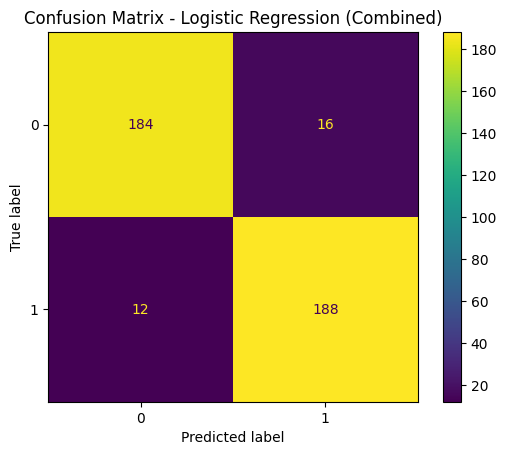

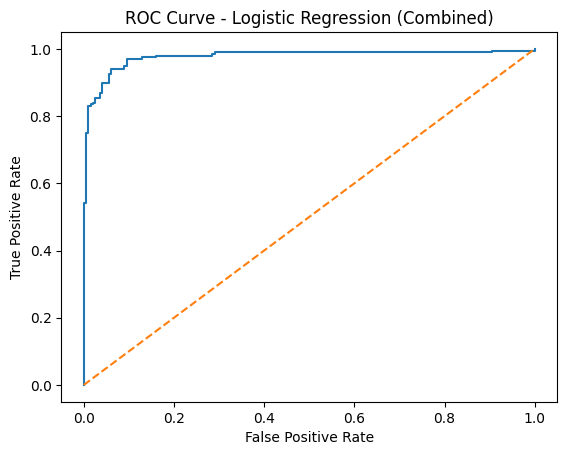

RF Combined
[[195   5]
 [ 11 189]]
              precision    recall  f1-score   support

           0     0.9466    0.9750    0.9606       200
           1     0.9742    0.9450    0.9594       200

    accuracy                         0.9600       400
   macro avg     0.9604    0.9600    0.9600       400
weighted avg     0.9604    0.9600    0.9600       400

0.99495


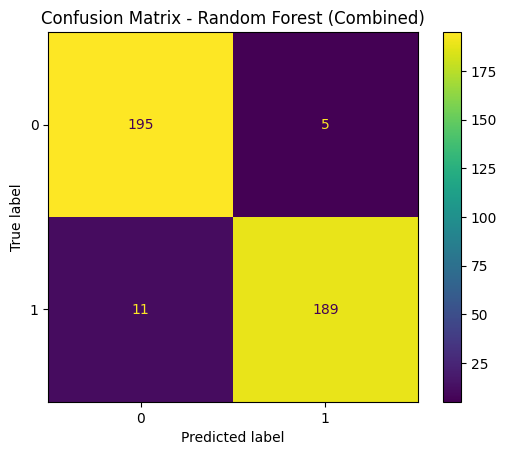

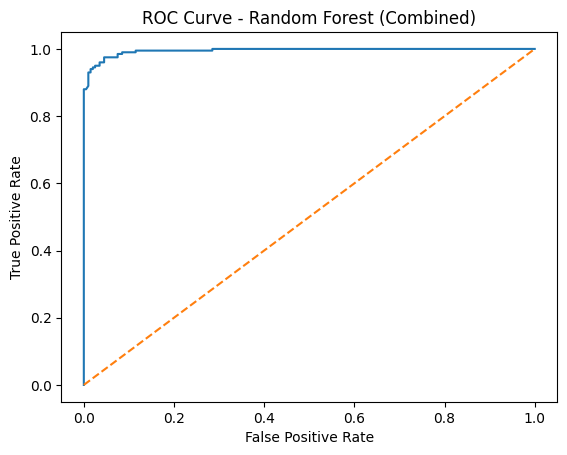

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

drop_cols = [c for c in ["sha256", "url", "label", "y"] if c in features_combined.columns]
Xc = features_combined.drop(columns=drop_cols)
yc = features_combined["y"].astype(int)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

lr_c = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=3000))
])

rf_c = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)

lr_c.fit(Xc_train, yc_train)
rf_c.fit(Xc_train, yc_train)

yc_prob_lr = lr_c.predict_proba(Xc_test)[:, 1]
yc_pred_lr = (yc_prob_lr >= 0.5).astype(int)

yc_prob_rf = rf_c.predict_proba(Xc_test)[:, 1]
yc_pred_rf = (yc_prob_rf >= 0.5).astype(int)

print("LR Combined")
print(confusion_matrix(yc_test, yc_pred_lr))
print(classification_report(yc_test, yc_pred_lr, digits=4))
print(roc_auc_score(yc_test, yc_prob_lr))

ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_lr)
plt.title("Confusion Matrix - Logistic Regression (Combined)")
plt.show()

fpr, tpr, _ = roc_curve(yc_test, yc_prob_lr)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression (Combined)")
plt.show()

print("RF Combined")
print(confusion_matrix(yc_test, yc_pred_rf))
print(classification_report(yc_test, yc_pred_rf, digits=4))
print(roc_auc_score(yc_test, yc_prob_rf))

ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_rf)
plt.title("Confusion Matrix - Random Forest (Combined)")
plt.show()

fpr, tpr, _ = roc_curve(yc_test, yc_prob_rf)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest (Combined)")
plt.show()

[[195   5]
 [  5 195]]
              precision    recall  f1-score   support

           0     0.9750    0.9750    0.9750       200
           1     0.9750    0.9750    0.9750       200

    accuracy                         0.9750       400
   macro avg     0.9750    0.9750    0.9750       400
weighted avg     0.9750    0.9750    0.9750       400

0.996675


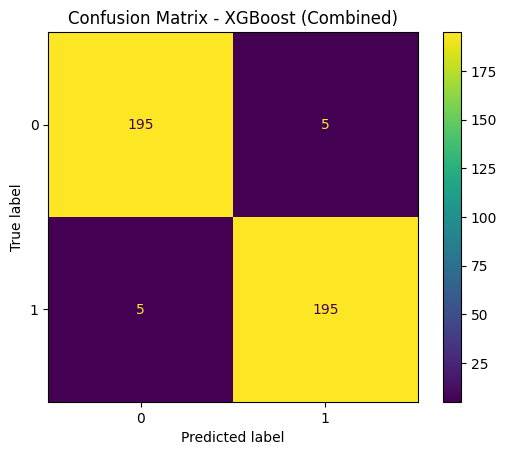

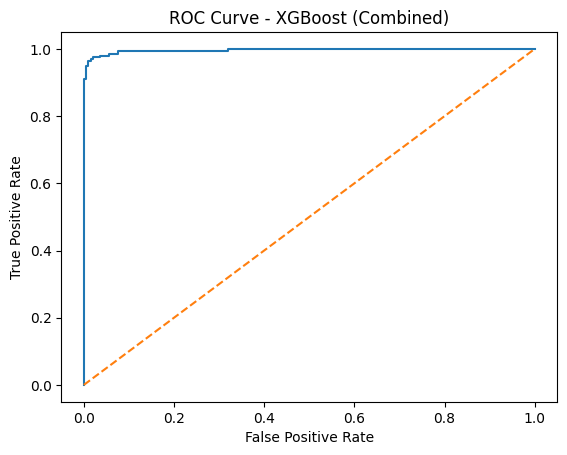

In [5]:
try:
    import xgboost as xgb
except ImportError:
    !pip -q install xgboost
    import xgboost as xgb

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

xgb_c = xgb.XGBClassifier(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    min_child_weight=1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

xgb_c.fit(Xc_train, yc_train)

yc_prob = xgb_c.predict_proba(Xc_test)[:, 1]
yc_pred = (yc_prob >= 0.5).astype(int)

print(confusion_matrix(yc_test, yc_pred))
print(classification_report(yc_test, yc_pred, digits=4))
print(roc_auc_score(yc_test, yc_prob))

ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred)
plt.title("Confusion Matrix - XGBoost (Combined)")
plt.show()

fpr, tpr, _ = roc_curve(yc_test, yc_prob)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost (Combined)")
plt.show()

In [6]:
import pandas as pd
from sklearn.metrics import roc_auc_score, confusion_matrix

rows_c = []

for name, model in [("LogReg_Combined", lr_c), ("RF_Combined", rf_c), ("XGBoost_Combined", xgb_c)]:
    prob = model.predict_proba(Xc_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    auc = roc_auc_score(yc_test, prob)
    cm = confusion_matrix(yc_test, pred)
    rows_c.append({
        "model": name,
        "roc_auc": float(auc),
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1])
    })

metrics_combined_df = pd.DataFrame(rows_c).sort_values("roc_auc", ascending=False).reset_index(drop=True)
metrics_combined_df

,model,roc_auc,tn,fp,fn,tp
0,XGBoost_Combined,0.996675,195,5,5,195
1,RF_Combined,0.994950,195,5,11,189
2,LogReg_Combined,0.976950,184,16,12,188


In [7]:
best_name_c = metrics_combined_df.loc[0, "model"]
best_model_c = {"LogReg_Combined": lr_c, "RF_Combined": rf_c, "XGBoost_Combined": xgb_c}[best_name_c]

prob_c = best_model_c.predict_proba(Xc_test)[:, 1]
pred_c = (prob_c >= 0.5).astype(int)

view_c = features_combined.loc[Xc_test.index, [c for c in ["sha256", "url", "label", "y"] if c in features_combined.columns]].copy()
view_c["pred"] = pred_c
view_c["proba"] = prob_c

fp_c = view_c[(view_c["y"] == 0) & (view_c["pred"] == 1)].sort_values("proba", ascending=False)
fn_c = view_c[(view_c["y"] == 1) & (view_c["pred"] == 0)].sort_values("proba", ascending=True)

best_name_c

'XGBoost_Combined'

In [8]:
from IPython.display import display

display(fp_c.head(20))
display(fn_c.head(20))

,sha256,url,label,y,pred,proba
921,d333f2cc0f2562a4bc0a24ed5d883e6ae224528db4d4ef...,https://web.snelstart.nl/ef30ad51-7bf5-4f6f-ba...,benign,0,1,0.909233
751,d1fb62f497b4f24e384f66a369c50d82cf2adef0414f2a...,https://samara.airbnb.com/,benign,0,1,0.668207
1323,481b70944926412dd5e3bccaf694c5db2925ff6f78faff...,https://allaccess.therapeuticresearch.com/,benign,0,1,0.624950
581,9de9899a3953b4b5c1ef8b34a56fba99a30e427d10c724...,https://studio.youtube.com/channel/uc2xucukpet...,benign,0,1,0.582597
1155,750d33344f1b44408eb169cb25be9c55a0ef029f39e19c...,https://agro.bndes.gov.br/,benign,0,1,0.550749


,sha256,url,label,y,pred,proba
266,a2f70e1e9f576233ab85cea8239f505faffb70efb00f4a...,https://glossvita.com/cart/checkout,phish,1,0,0.001833
1673,c49dda7e71623ce21e5dde2ec734e1fbc794852cd2c9e8...,https://trezorstartfaq.groovehq.com/help/en-us,phish,1,0,0.116130
638,dd3c093a240eee646524a8103a9a27aae68baf85f19466...,https://app-centralbankwebsite-prod-eus2.azure...,phish,1,0,0.119437
416,532c99c78c09f8fb34bb1936f3c2713e2ec49549b0abc1...,https://www.powr.io/media-gallery/i/39114908#page,phish,1,0,0.347891
1903,01fd44e82debe32560807e58350db715ab26945e93230f...,https://premierpet-golden.shop/inicio/quiz/,phish,1,0,0.439167


In [9]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"f1": "f1", "roc_auc": "roc_auc", "accuracy": "accuracy"}

models_c = {"LogReg_Combined": lr_c, "RF_Combined": rf_c, "XGBoost_Combined": xgb_c}

cv_rows_c = []
for name, m in models_c.items():
    out = cross_validate(m, Xc, yc, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows_c.append({
        "model": name,
        "f1_mean": float(np.mean(out["test_f1"])),
        "f1_std": float(np.std(out["test_f1"])),
        "auc_mean": float(np.mean(out["test_roc_auc"])),
        "auc_std": float(np.std(out["test_roc_auc"])),
        "acc_mean": float(np.mean(out["test_accuracy"])),
        "acc_std": float(np.std(out["test_accuracy"]))
    })

cv_combined_df = pd.DataFrame(cv_rows_c).sort_values("auc_mean", ascending=False).reset_index(drop=True)
cv_combined_df

,model,f1_mean,f1_std,auc_mean,auc_std,acc_mean,acc_std
0,XGBoost_Combined,0.957676,0.009369,0.992790,0.002026,0.9580,0.008718
1,RF_Combined,0.948068,0.006158,0.989640,0.002007,0.9485,0.005831
2,LogReg_Combined,0.911305,0.008821,0.967625,0.006187,0.9100,0.009874


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

feat_names_c = Xc.columns.tolist()

rf_imp_c = pd.Series(rf_c.feature_importances_, index=feat_names_c).sort_values(ascending=False)
xgb_imp_c = pd.Series(xgb_c.feature_importances_, index=feat_names_c).sort_values(ascending=False)

top_n = 20
rf_top_c = rf_imp_c.head(top_n).reset_index()
rf_top_c.columns = ["feature", "importance"]

xgb_top_c = xgb_imp_c.head(top_n).reset_index()
xgb_top_c.columns = ["feature", "importance"]

rf_top_c

,feature,importance
0,num_scripts,0.085420
1,num_external_links,0.076751
2,num_script_src,0.060163
3,path_len,0.055887
4,num_links,0.054546
5,html_len,0.054162
6,tag_count,0.052461
7,count_slash,0.045057
8,path_depth,0.043556
9,unique_tag_count,0.035915


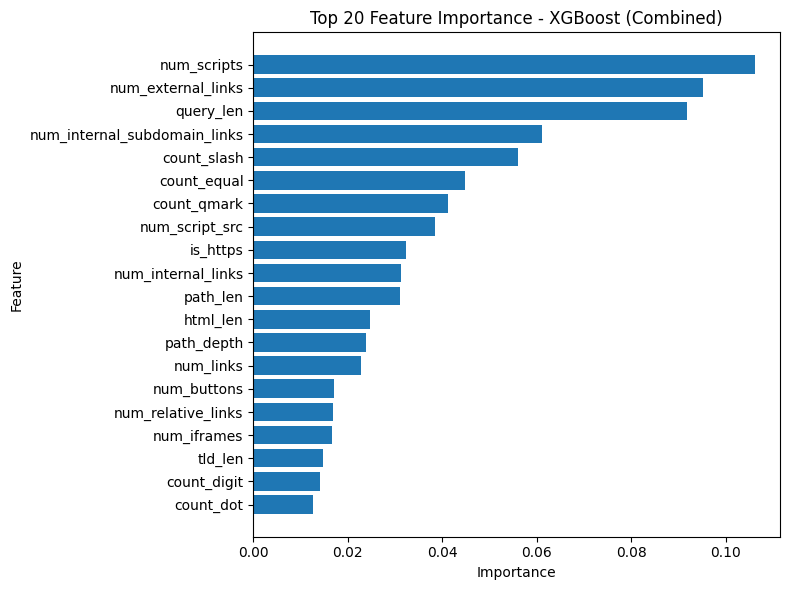

In [11]:
def plot_top_importance(df, title):
    plt.figure(figsize=(8, 6))
    plt.barh(df["feature"].iloc[::-1], df["importance"].iloc[::-1])
    plt.title(title)
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

plot_top_importance(xgb_top_c, "Top 20 Feature Importance - XGBoost (Combined)")

d:\anaconda\envs\py311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


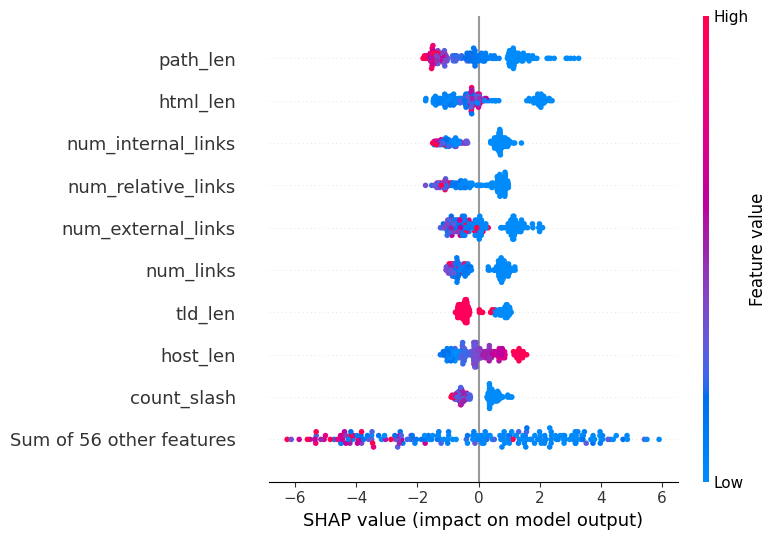

In [12]:
try:
    import shap
except ImportError:
    !pip -q install shap
    import shap

import matplotlib.pyplot as plt

Xc_sample = Xc_test.sample(n=min(200, len(Xc_test)), random_state=42)
explainer_c = shap.Explainer(xgb_c, Xc_sample)
sv_c = explainer_c(Xc_sample)

shap.plots.beeswarm(sv_c, show=False)
plt.tight_layout()
plt.show()

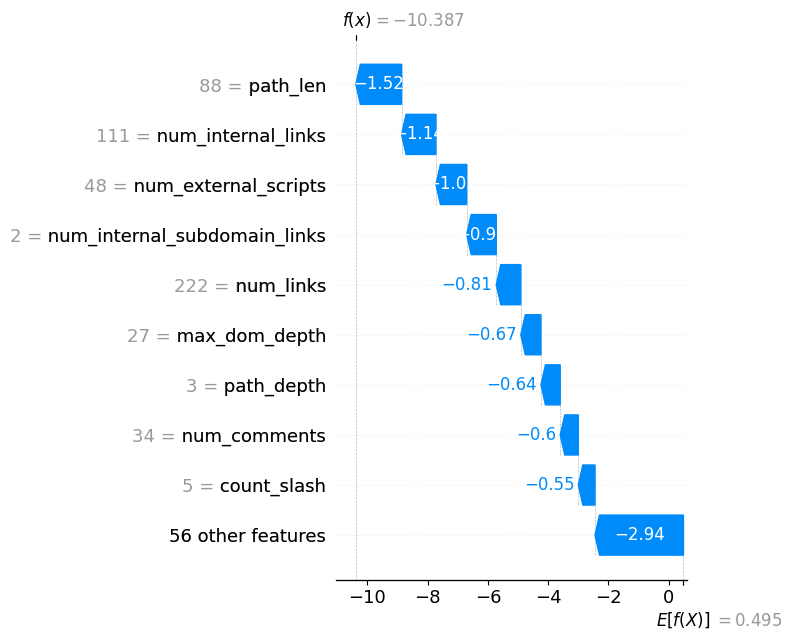

In [13]:
import matplotlib.pyplot as plt

idx = Xc_test.index[0]
x_one_c = Xc_test.loc[[idx]]
sv_one_c = explainer_c(x_one_c)

shap.plots.waterfall(sv_one_c[0], show=False)
plt.tight_layout()
plt.show()

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, roc_auc_score, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import numpy as np

X_tr, X_val, y_tr, y_val = train_test_split(
    Xc_train, yc_train, test_size=0.25, random_state=42, stratify=yc_train
)

if best_name_c == "LogReg_Combined":
    m1 = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=3000))])
    m2 = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=3000))])
elif best_name_c == "RF_Combined":
    m1 = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
    m2 = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
else:
    m1 = xgb.XGBClassifier(**xgb_c.get_params())
    m2 = xgb.XGBClassifier(**xgb_c.get_params())

m1.fit(X_tr, y_tr)
val_prob = m1.predict_proba(X_val)[:, 1]
p, r, th = precision_recall_curve(y_val, val_prob)

p2, r2 = p[1:], r[1:]
f1 = (2 * p2 * r2) / (p2 + r2 + 1e-12)
best_i = int(np.argmax(f1))
best_th_c = float(th[best_i])

m2.fit(Xc_train, yc_train)
test_prob_c2 = m2.predict_proba(Xc_test)[:, 1]
test_pred_c2 = (test_prob_c2 >= best_th_c).astype(int)

best_th_c, roc_auc_score(yc_test, test_prob_c2), confusion_matrix(yc_test, test_pred_c2)

(0.30684614181518555,
 0.996675,
 array([[188,  12],
        [  3, 197]]))

              precision    recall  f1-score   support

           0     0.9843    0.9400    0.9616       200
           1     0.9426    0.9850    0.9633       200

    accuracy                         0.9625       400
   macro avg     0.9634    0.9625    0.9625       400
weighted avg     0.9634    0.9625    0.9625       400

[[188  12]
 [  3 197]]


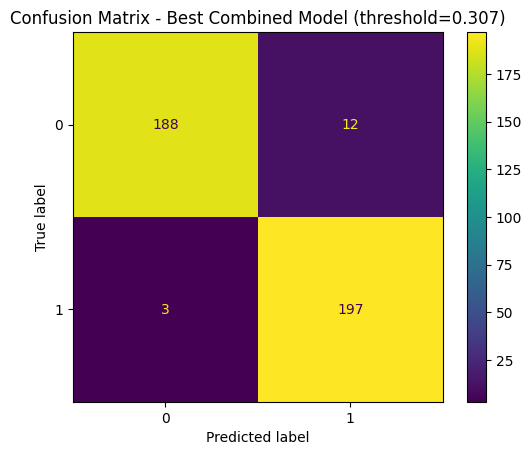

In [15]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print(classification_report(yc_test, test_pred_c2, digits=4))
print(confusion_matrix(yc_test, test_pred_c2))

ConfusionMatrixDisplay.from_predictions(yc_test, test_pred_c2)
plt.title(f"Confusion Matrix - Best Combined Model (threshold={best_th_c:.3f})")
plt.show()

In [16]:
from IPython.display import display

view_th_c = features_combined.loc[Xc_test.index, [c for c in ["sha256", "url", "label", "y"] if c in features_combined.columns]].copy()
view_th_c["pred"] = test_pred_c2
view_th_c["proba"] = test_prob_c2

fp_th_c = view_th_c[(view_th_c["y"] == 0) & (view_th_c["pred"] == 1)].sort_values("proba", ascending=False)
fn_th_c = view_th_c[(view_th_c["y"] == 1) & (view_th_c["pred"] == 0)].sort_values("proba", ascending=True)

display(fp_th_c.head(20))
display(fn_th_c.head(20))

,sha256,url,label,y,pred,proba
921,d333f2cc0f2562a4bc0a24ed5d883e6ae224528db4d4ef...,https://web.snelstart.nl/ef30ad51-7bf5-4f6f-ba...,benign,0,1,0.909233
751,d1fb62f497b4f24e384f66a369c50d82cf2adef0414f2a...,https://samara.airbnb.com/,benign,0,1,0.668207
1323,481b70944926412dd5e3bccaf694c5db2925ff6f78faff...,https://allaccess.therapeuticresearch.com/,benign,0,1,0.624950
581,9de9899a3953b4b5c1ef8b34a56fba99a30e427d10c724...,https://studio.youtube.com/channel/uc2xucukpet...,benign,0,1,0.582597
1155,750d33344f1b44408eb169cb25be9c55a0ef029f39e19c...,https://agro.bndes.gov.br/,benign,0,1,0.550749
1028,b98242e2137905c53de729ac90908fcb7b32605e7e0512...,https://app.saluteelavoro.eu/sallav/ipdfviewer...,benign,0,1,0.482900
931,fe086ac6b7fd07ad30f84a4ad2fe631e7629bfd69dfd11...,https://gcps.powerschool.com/teachers/studentp...,benign,0,1,0.482565
1030,3bed1e9b18a0c94ad49bd0e412efcfe6c18bae306e12b9...,https://pcm.annas-archive.org/,benign,0,1,0.434298
1168,b5b29913aff8644011fe0c885e4ba2df465853bf9b65f7...,https://ccbcllp.cchifirm.ca/2/login/,benign,0,1,0.433352
1064,09af4e95861ce77883ba0b169dabfc97d4257aee750fd3...,https://linktr.ee/PoppyPlaytimeCo,benign,0,1,0.413691


,sha256,url,label,y,pred,proba
266,a2f70e1e9f576233ab85cea8239f505faffb70efb00f4a...,https://glossvita.com/cart/checkout,phish,1,0,0.001833
1673,c49dda7e71623ce21e5dde2ec734e1fbc794852cd2c9e8...,https://trezorstartfaq.groovehq.com/help/en-us,phish,1,0,0.116130
638,dd3c093a240eee646524a8103a9a27aae68baf85f19466...,https://app-centralbankwebsite-prod-eus2.azure...,phish,1,0,0.119437


In [17]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score, confusion_matrix

root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

report_dir = root / "data" / "processed" / "report_tables"

ablation_rows = []

if (report_dir / "url_metrics_testset.csv").exists():
    url_m = pd.read_csv(report_dir / "url_metrics_testset.csv")
    if "model" in url_m.columns and "roc_auc" in url_m.columns:
        url05 = url_m[~url_m["model"].astype(str).str.contains("threshold", case=False, na=False)]
        if len(url05) > 0:
            r = url05.sort_values("roc_auc", ascending=False).iloc[0]
            ablation_rows.append({"setting":"URL_only(0.5)","model":r["model"],"roc_auc":float(r["roc_auc"]), "tn":int(r["tn"]), "fp":int(r["fp"]), "fn":int(r["fn"]), "tp":int(r["tp"])})
        urlth = url_m[url_m["model"].astype(str).str.contains("threshold", case=False, na=False)]
        if len(urlth) > 0:
            r = urlth.sort_values("roc_auc", ascending=False).iloc[0]
            ablation_rows.append({"setting":"URL_only(threshold)","model":r["model"],"roc_auc":float(r["roc_auc"]), "tn":int(r["tn"]), "fp":int(r["fp"]), "fn":int(r["fn"]), "tp":int(r["tp"])})

if (report_dir / "html_metrics_testset.csv").exists():
    html_m = pd.read_csv(report_dir / "html_metrics_testset.csv")
    if "model" in html_m.columns and "roc_auc" in html_m.columns:
        html05 = html_m[~html_m["model"].astype(str).str.contains("threshold", case=False, na=False)]
        if len(html05) > 0:
            r = html05.sort_values("roc_auc", ascending=False).iloc[0]
            ablation_rows.append({"setting":"HTML_only(0.5)","model":r["model"],"roc_auc":float(r["roc_auc"]), "tn":int(r["tn"]), "fp":int(r["fp"]), "fn":int(r["fn"]), "tp":int(r["tp"])})
        htmlth = html_m[html_m["model"].astype(str).str.contains("threshold", case=False, na=False)]
        if len(htmlth) > 0:
            r = htmlth.sort_values("roc_auc", ascending=False).iloc[0]
            ablation_rows.append({"setting":"HTML_only(threshold)","model":r["model"],"roc_auc":float(r["roc_auc"]), "tn":int(r["tn"]), "fp":int(r["fp"]), "fn":int(r["fn"]), "tp":int(r["tp"])})

if "metrics_combined_df" in globals():
    r = metrics_combined_df.sort_values("roc_auc", ascending=False).iloc[0]
    ablation_rows.append({"setting":"Combined(0.5)","model":r["model"],"roc_auc":float(r["roc_auc"]), "tn":int(r["tn"]), "fp":int(r["fp"]), "fn":int(r["fn"]), "tp":int(r["tp"])})

if "test_prob_c2" in globals() and "test_pred_c2" in globals() and "yc_test" in globals():
    cm = confusion_matrix(yc_test, test_pred_c2)
    ablation_rows.append({"setting":"Combined(threshold)","model":"Best_Combined(threshold)","roc_auc":float(roc_auc_score(yc_test, test_prob_c2)), "tn":int(cm[0,0]), "fp":int(cm[0,1]), "fn":int(cm[1,0]), "tp":int(cm[1,1])})

ablation_df = pd.DataFrame(ablation_rows)
ablation_df

,setting,model,roc_auc,tn,fp,fn,tp
0,URL_only(0.5),RF,0.967738,187,13,26,174
1,URL_only(threshold),RF(threshold),0.967738,189,11,28,172
2,HTML_only(0.5),XGBoost_HTML,0.988725,188,12,10,190
3,HTML_only(threshold),Best_HTML(threshold),0.988725,183,17,8,192
4,Combined(0.5),XGBoost_Combined,0.996675,195,5,5,195
5,Combined(threshold),Best_Combined(threshold),0.996675,188,12,3,197


In [18]:
from pathlib import Path
import pandas as pd

root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

report_dir = root / "data" / "processed" / "report_tables"
report_dir.mkdir(parents=True, exist_ok=True)

ablation_df.to_csv(report_dir / "ablation_url_html_combined.csv", index=False)

metrics_combined_df.to_csv(report_dir / "combined_metrics_testset.csv", index=False)
cv_combined_df.to_csv(report_dir / "combined_metrics_cv5.csv", index=False)
rf_top_c.to_csv(report_dir / "combined_rf_top20_features.csv", index=False)
xgb_top_c.to_csv(report_dir / "combined_xgb_top20_features.csv", index=False)

fp_th_c.head(50).to_csv(report_dir / "combined_fp_top50.csv", index=False)
fn_th_c.head(50).to_csv(report_dir / "combined_fn_top50.csv", index=False)

str(report_dir)

'c:\\Users\\14176\\Desktop\\Honours Project\\Hons Project\\data\\processed\\report_tables'